# ML-guided selection of graph-query strategies in Apache Spark

**The problem in one line:** Spark can run our two-hop graph query, `(a)->(b)->(c)`, in three ways:
**native** (GraphFrames `find`), **edge-join** (a plain self-join) and **hub-split** (splits very busy "hub" vertices across a grid).
No single way is fastest for every graph. We train a model that looks at a graph's shape **before** running it and picks the fastest way.

This notebook follows the six-step data-visualisation story:

| Step | Data-visualisation process | What it means in our project | Where in this notebook |
|---|---|---|---|
| 1 | Identify data sources | 62 synthetic graphs (5 families + a hub sweep) | Step 1 |
| 2 | Extract data | Each graph is run on Spark with every strategy, and the times are recorded | Step 2 |
| 3 | Map data (format + clean) | 13 features per graph; label = the fastest strategy | Step 3 |
| 4 | Upload to one standard store | Everything goes into one table, `combined_table.csv` (62 rows) | Step 4 |
| 5 | Graphically represent | Train, validate and test the models; compare them with the baselines | Step 5 |
| 6 | Save and share reports | Results file, chart PNGs and a Tableau "decision explorer" | Step 6 |

Every chart has two short notes: **How we got it** and **What it tells us**.
Run it with *Kernel → Restart & Run All*. It takes about 2–3 minutes, and the last cell checks that the numbers are the same as in our report.

In [1]:
# Setup: libraries, paths, fixed seeds (so every run gives the same numbers)
import os, sys, json, warnings
import numpy as np, pandas as pd
%matplotlib inline
import matplotlib, matplotlib.ticker
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, Wedge
from IPython.display import display, Markdown
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, f1_score, confusion_matrix
warnings.filterwarnings("ignore")

def find_repo(start):
    d = os.path.abspath(start)
    while not os.path.exists(os.path.join(d, "datasets", "derived", "training", "combined_table.csv")):
        if os.path.dirname(d) == d:
            raise SystemExit("Open this notebook from inside the project folder.")
        d = os.path.dirname(d)
    return d

REPO = find_repo(os.getcwd()); sys.path.insert(0, REPO)
from ml.build_feature_table import FEATURE_COLUMNS          # the 11 features computed from each graph

TABLE = os.path.join(REPO, "datasets", "derived", "training", "combined_table.csv")
OUT = os.path.join(REPO, "datasets", "derived", "review"); os.makedirs(OUT, exist_ok=True)
SEED, NTREES = 0, 300
np.random.seed(SEED)

STRATS = ["edgejoin__aqe_off", "native__aqe_on", "hypercube_unified__aqe_off"]   # the 3 strategies
NAME = {"edgejoin__aqe_off": "edge-join", "native__aqe_on": "native", "hypercube_unified__aqe_off": "hub-split"}
CLASS_OF = {"edgejoin__aqe_off": "edgejoin", "native__aqe_on": "native", "hypercube_unified__aqe_off": "hubsplit"}
CLASSES = ["edgejoin", "hubsplit", "native"]
COL = {"edge-join": "#4C78A8", "native": "#72B7B2", "hub-split": "#E45756", "ML selector": "#2E8B57", "baseline": "#B0B0B0"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .3, "axes.spines.top": False, "axes.spines.right": False})
RES = {}
# Style for the charts that go on the slides: big fonts and plain-English axis titles, readable on a projector.
SLIDE = {"font.size": 15, "axes.titlesize": 17, "axes.labelsize": 16, "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14}
C = {"edge-join": "#4C78A8", "native": "#72B7B2", "hub-split": "#E45756", "ours": "#2E8B57", "base": "#A9A9A9"}
def save_slide(fig, name):
    fig.tight_layout(); fig.savefig(f"{OUT}/{name}", dpi=200); plt.show()
print("Project folder:", REPO)

Project folder: /home/claude/rayirth556/hypergraph


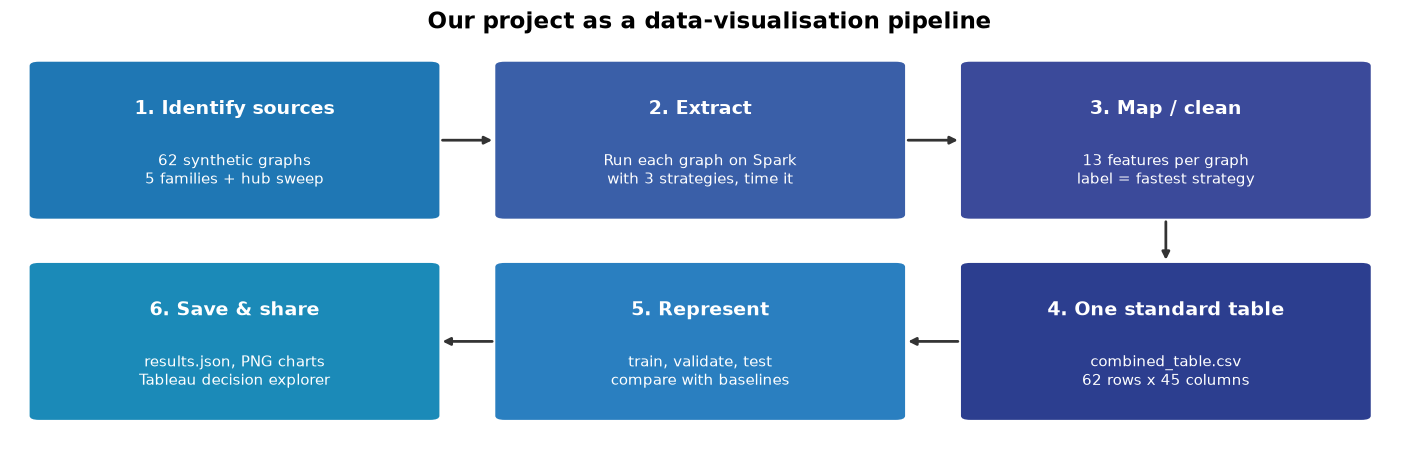

In [2]:
# The story in one picture
steps = [("1. Identify sources", "62 synthetic graphs\n5 families + hub sweep"),
         ("2. Extract", "Run each graph on Spark\nwith 3 strategies, time it"),
         ("3. Map / clean", "13 features per graph\nlabel = fastest strategy"),
         ("4. One standard table", "combined_table.csv\n62 rows x 45 columns"),
         ("5. Represent", "train, validate, test\ncompare with baselines"),
         ("6. Save & share", "results.json, PNG charts\nTableau decision explorer")]
fig, ax = plt.subplots(figsize=(13, 4.2)); ax.axis("off"); ax.set_xlim(0, 3); ax.set_ylim(0, 2)
pos = [(0, 1), (1, 1), (2, 1), (2, 0), (1, 0), (0, 0)]          # snake layout like the reference image
shade = ["#1f77b4", "#3a5fa8", "#3b4a9a", "#2c3e8f", "#2a7fc0", "#1b8ab8"]
for (t, d), (x, y), c in zip(steps, pos, shade):
    ax.add_patch(FancyBboxPatch((x + .06, y + .12), .84, .74, boxstyle="round,pad=0.02", fc=c, ec="none"))
    ax.text(x + .48, y + .62, t, color="white", ha="center", fontsize=12.5, weight="bold")
    ax.text(x + .48, y + .34, d, color="white", ha="center", fontsize=10, va="center")
for (x1, y1), (x2, y2) in zip(pos[:-1], pos[1:]):
    if y1 == y2:
        dx = .1 if x2 > x1 else -.1
        ax.annotate("", (x2 + .48 - .44 * np.sign(x2 - x1) - dx * 0, y2 + .49), (x1 + .48 + .44 * np.sign(x2 - x1), y1 + .49),
                    arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.8))
    else:
        ax.annotate("", (x2 + .48, y2 + .88), (x1 + .48, y1 + .1), arrowprops=dict(arrowstyle="-|>", color="#333", lw=1.8))
ax.set_title("Our project as a data-visualisation pipeline", fontsize=15, weight="bold")
plt.tight_layout(); plt.savefig(f"{OUT}/00_story.png", dpi=130); plt.show()

## Step 1: Identify the data sources
We did not download a dataset. We **generated** graphs with our own Python generators (`datagen/generators.py`, `datagen/hub_sweep.py`) so that we control their shape:

* **uniform**: every vertex has about the same number of edges (no hubs)
* **powerlaw_balanced, in_heavy, out_heavy, multi_hub**: a few vertices have far more edges than the rest (skew)
* **hub_sweep**: we plant 1–8 hubs and slowly raise how much of the work goes through them, to find where hub-split starts to win

Each graph is stored as a Parquet edge list (`src, dst`). Here we load the final table (one row per graph) and look at what we have.

,graphs,total edges,vertices per graph,edges per graph,two-hop paths per graph
0,62,116.4 M,"100,000 – 1,000,000",0.70 M – 7.0 M,4.5 M – 981 M


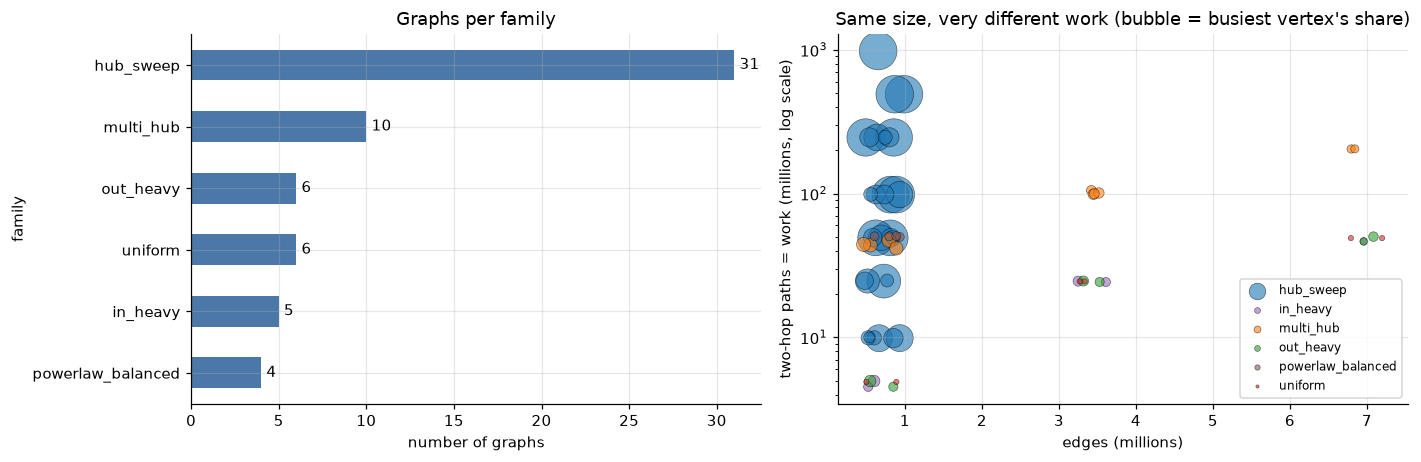

**Why this chart:** it shows our data is varied (6 families, very different workloads), so a single fixed strategy cannot fit every graph. This is the reason a selector is needed.
**How we got it:** we counted the rows per family (bar chart). For the bubble chart, each graph is placed by its number of edges (x) and its number of two-hop results, i.e. the work (y); a bigger bubble means more of the work sits on one vertex.
**What it tells us:** 62 graphs and 116 M edges in total. Half the graphs (31) are the hub sweep, built to test the hub case.
Graphs with the **same** number of edges (about 0.7 M) need anywhere from **4.5 M to 981 M** paths of work, and the big bubbles (one heavy vertex) sit at the top.
So **size alone cannot pick the strategy**; we need features that describe the graph's shape.

In [3]:
df = pd.read_csv(TABLE)
df["vertices"] = np.expm1(df.log_num_vertices).round().astype(int)
df["edges"] = np.expm1(df.log_num_edges).round().astype(int)
df["two_hop_paths"] = df.raw_work_sum                       # exact number of (a)->(b)->(c) results
fam = df.family.value_counts()
dims = pd.DataFrame({"graphs": [len(df)], "total edges": [f"{df.edges.sum()/1e6:.1f} M"],
                     "vertices per graph": [f"{df.vertices.min():,} – {df.vertices.max():,}"],
                     "edges per graph": [f"{df.edges.min()/1e6:.2f} M – {df.edges.max()/1e6:.1f} M"],
                     "two-hop paths per graph": [f"{df.two_hop_paths.min()/1e6:.1f} M – {df.two_hop_paths.max()/1e6:.0f} M"]})
display(dims)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
fam.sort_values().plot.barh(ax=ax[0], color="#4C78A8")
for i, v in enumerate(fam.sort_values()): ax[0].text(v + .3, i, str(v), va="center")
ax[0].set_title("Graphs per family"); ax[0].set_xlabel("number of graphs")
cmap = dict(zip(fam.index, plt.cm.tab10.colors))
jit = np.random.RandomState(1).uniform(-.25, .25, len(df))          # small sideways shift so dots do not hide each other
for f, g in df.groupby("family"):
    ax[1].scatter(g.edges / 1e6 + jit[g.index], g.two_hop_paths / 1e6, s=g.work_max_share * 600 + 12, alpha=.6, color=cmap[f], edgecolor="k", lw=.4, label=f)
ax[1].set_yscale("log"); ax[1].set_xlabel("edges (millions)"); ax[1].set_ylabel("two-hop paths = work (millions, log scale)")
ax[1].set_title("Same size, very different work (bubble = busiest vertex's share)"); ax[1].legend(fontsize=8, markerscale=.6, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/01_dataset.png", dpi=130); plt.show()
RES["n_graphs"] = len(df); RES["total_edges_M"] = round(df.edges.sum() / 1e6, 1)
small = df[df.edges < 1e6]
display(Markdown(f"""**Why this chart:** it shows our data is varied (6 families, very different workloads), so a single fixed strategy cannot fit every graph. This is the reason a selector is needed.
**How we got it:** we counted the rows per family (bar chart). For the bubble chart, each graph is placed by its number of edges (x) and its number of two-hop results, i.e. the work (y); a bigger bubble means more of the work sits on one vertex.
**What it tells us:** {len(df)} graphs and {df.edges.sum()/1e6:.0f} M edges in total. Half the graphs ({fam['hub_sweep']}) are the hub sweep, built to test the hub case.
Graphs with the **same** number of edges (about 0.7 M) need anywhere from **{small.two_hop_paths.min()/1e6:.1f} M to {small.two_hop_paths.max()/1e6:.0f} M** paths of work, and the big bubbles (one heavy vertex) sit at the top.
So **size alone cannot pick the strategy**; we need features that describe the graph's shape."""))

## Step 2: Extract the data (Spark benchmark)
**Big data tool:** Apache Spark 3.5.5 (local mode) + GraphFrames 0.8.3, reading Parquet.
For every graph we started a fresh Spark session, loaded the edges (`spark.read.parquet`, in `bench/phase1_worker.py`),
checked that every strategy returns the **same** number of paths (correctness gate), did a warm-up run and then
several timed runs in shuffled order. We keep the **median** time per graph and strategy.

*This step took hours, so we do not re-run Spark in the review. Its output (the medians) is already in the table.*
Below we look at what the timings say.

timed Spark runs behind these medians: 735  (62 graphs x 3 strategies, 2-5 runs each)


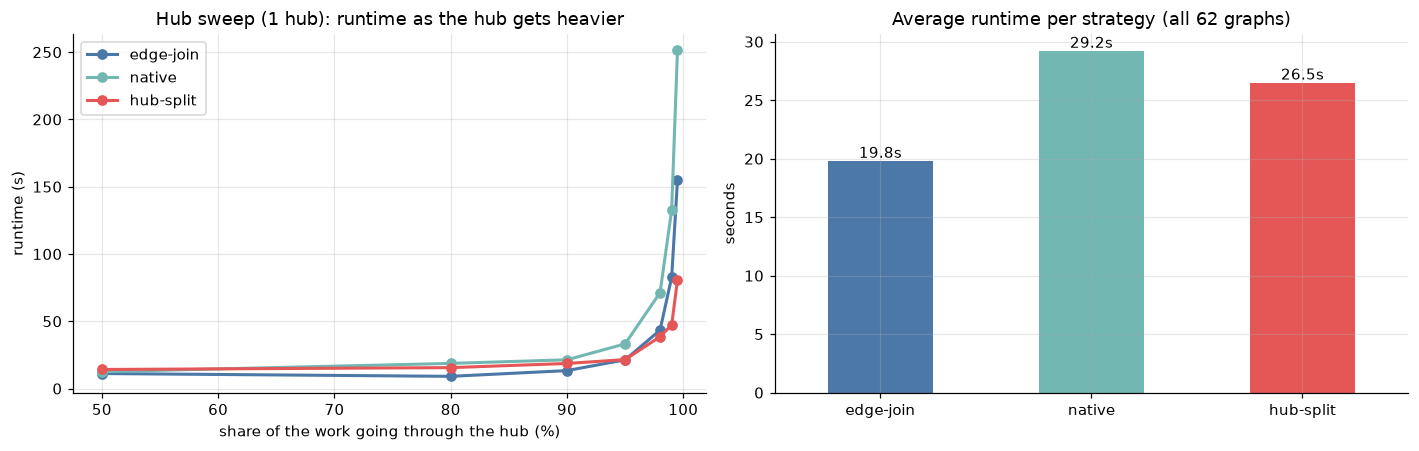

**Why this chart:** it proves the core problem with real Spark timings: the fastest strategy changes as the hub gets heavier, so no one strategy is always best.
**How we got it:** the median Spark runtime of each strategy on the one-hub graphs (line chart), and the average over all graphs (bar chart).
**What it tells us:** while the hub carries little work, edge-join is fastest. When the hub carries about **98%** or more of the work,
edge-join's time shoots up because one Spark task gets all the hub's paths, and **hub-split** becomes the fastest.
The fastest choice **changes with the graph's shape**, and that is why a model is needed.

In [4]:
T = np.column_stack([df[f"median_total_s__{s}"].values for s in STRATS])        # 62 x 3 median seconds
runs_used = int(sum(df[f"n_valid_runs__{s}"].sum() for s in STRATS))
print(f"timed Spark runs behind these medians: {runs_used}  (62 graphs x 3 strategies, 2-5 runs each)")
sw = df[(df.family == "hub_sweep") & (df.hub_count == 1) & (df.seed == 101)].sort_values("hub_work_share_planned")
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for k, s in enumerate(STRATS):
    ax[0].plot(sw.hub_work_share_planned * 100, sw[f"median_total_s__{s}"], "o-", lw=2, color=COL[NAME[s]], label=NAME[s])
ax[0].set_xlabel("share of the work going through the hub (%)"); ax[0].set_ylabel("runtime (s)")
ax[0].set_title("Hub sweep (1 hub): runtime as the hub gets heavier"); ax[0].legend()
avg = pd.Series(T.mean(0), index=[NAME[s] for s in STRATS])
avg.plot.bar(ax=ax[1], color=[COL[n] for n in avg.index], rot=0)
for i, v in enumerate(avg): ax[1].text(i, v + .3, f"{v:.1f}s", ha="center")
ax[1].set_title("Average runtime per strategy (all 62 graphs)"); ax[1].set_ylabel("seconds")
plt.tight_layout(); plt.savefig(f"{OUT}/02_runtimes.png", dpi=130); plt.show()
cross = sw[sw["median_total_s__hypercube_unified__aqe_off"] < sw["median_total_s__edgejoin__aqe_off"]].hub_work_share_planned.min()
display(Markdown(f"""**Why this chart:** it proves the core problem with real Spark timings: the fastest strategy changes as the hub gets heavier, so no one strategy is always best.
**How we got it:** the median Spark runtime of each strategy on the one-hub graphs (line chart), and the average over all graphs (bar chart).
**What it tells us:** while the hub carries little work, edge-join is fastest. When the hub carries about **{cross*100:.0f}%** or more of the work,
edge-join's time shoots up because one Spark task gets all the hub's paths, and **hub-split** becomes the fastest.
The fastest choice **changes with the graph's shape**, and that is why a model is needed."""))

## Step 3: Map the data (feature engineering + labels)
Each graph is turned into **13 numbers** that can be computed *before* running the query:

* **11 base features** (`ml/build_feature_table.py`): size (vertices, edges, active fraction), degree skew (in/out Gini, top-0.1% degrees) and two-hop work (total paths, busiest vertex's share, number of hub vertices, hubs' share).
* **2 derived features** (computed here): `log_hub_work` = paths through the hubs, and `log_max_work` = paths through the single busiest vertex.

Counts are put through `log(1 + x)` so that huge numbers become comparable. **Label** = the strategy with the lowest median runtime.

input matrix X: 62 graphs x 13 features


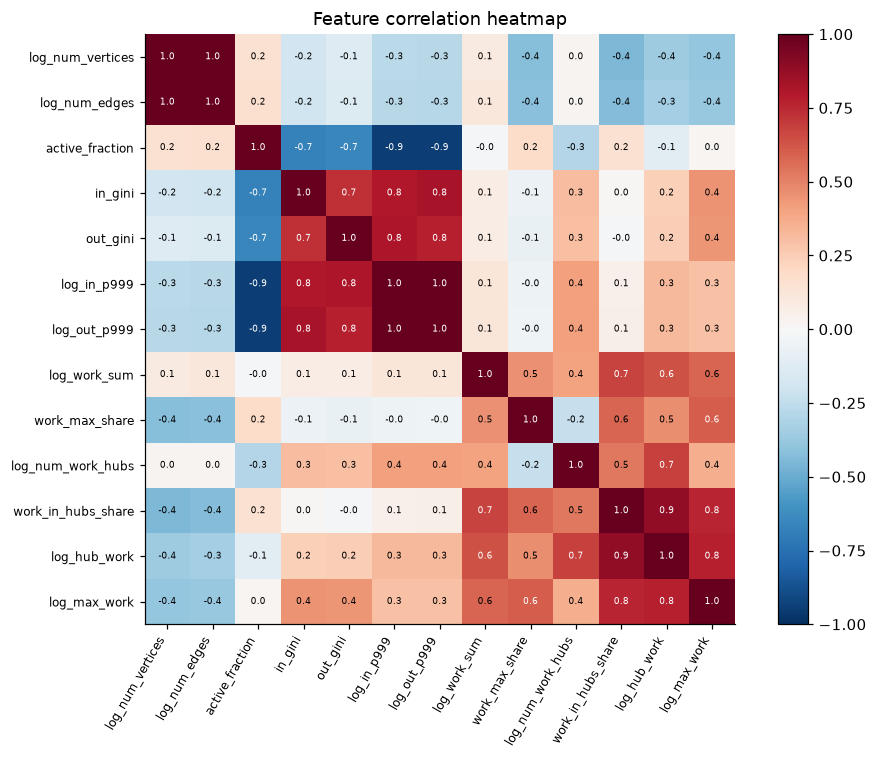

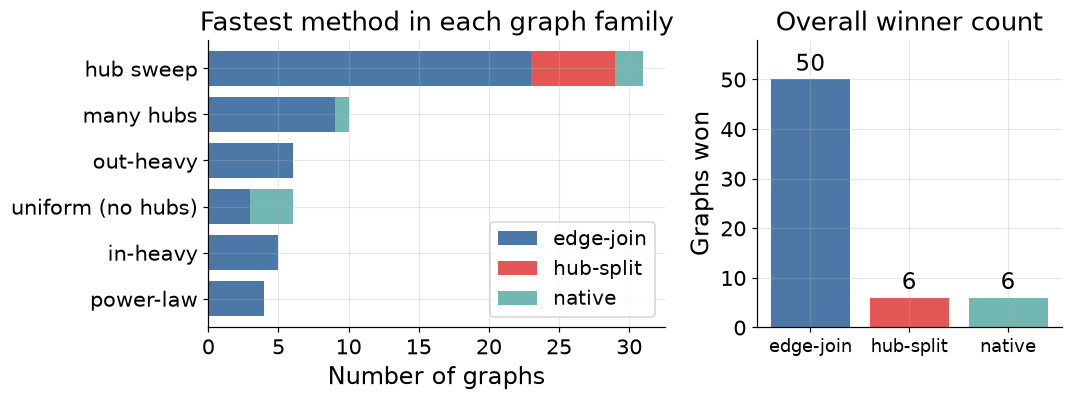

**Why these charts:** they justify our features (they carry different information) and our metrics (labels are imbalanced, so accuracy alone would mislead).
**How we got it:** the Pearson correlation between every pair of the 13 features (heatmap; red = they rise together, blue = one rises as the other falls), and a count of which method was fastest, per family and overall (bar charts, X-axis = number of graphs).
**What it tells us:** the features form three groups that move together: **size** (vertices, edges), **degree skew** (Gini and top-0.1% degrees, which are high when active_fraction is low) and **hub work** (the work and hub features at the bottom right).
The groups are only weakly related to each other, so each one adds new information and all of them are kept.
The labels are **imbalanced**: edge-join wins 50 of 62 graphs (80.6%). So a "model" that always says edge-join already gets 80.6% accuracy.
That is our **baseline**, and it is why we also report **precision** and **F1-score**, which do not reward ignoring the rare classes.

In [5]:
df["log_hub_work"] = np.log1p(df.raw_work_sum * df.work_in_hubs_share)
df["log_max_work"] = np.log1p(df.raw_work_sum * df.work_max_share)
FEATS = list(FEATURE_COLUMNS) + ["log_hub_work", "log_max_work"]
X = df[FEATS].values
y = df.best_class.values
LOGT = np.log(T)
print(f"input matrix X: {X.shape[0]} graphs x {X.shape[1]} features")

fig, ax = plt.subplots(figsize=(9, 7)); ax = [ax]
corr = df[FEATS].corr()
im = ax[0].imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax[0].set_xticks(range(len(FEATS))); ax[0].set_xticklabels(FEATS, rotation=60, ha="right", fontsize=8)
ax[0].set_yticks(range(len(FEATS))); ax[0].set_yticklabels(FEATS, fontsize=8); ax[0].grid(False)
for i in range(len(FEATS)):
    for j in range(len(FEATS)):
        v = corr.iloc[i, j]; ax[0].text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=6, color="white" if abs(v) > .6 else "black")
plt.colorbar(im, ax=ax[0], fraction=.04); ax[0].set_title("Feature correlation heatmap")
plt.tight_layout(); plt.savefig(f"{OUT}/03_feature_heatmap.png", dpi=130); plt.show()
cnt = pd.Series(y).value_counts().reindex(CLASSES)

# Slide chart: which method was fastest, per family and overall  (slide "Results of Preprocessing")
fam_name = {"hub_sweep": "hub sweep", "multi_hub": "many hubs", "out_heavy": "out-heavy", "uniform": "uniform (no hubs)", "in_heavy": "in-heavy", "powerlaw_balanced": "power-law"}
lab = {"edgejoin": "edge-join", "hubsplit": "hub-split", "native": "native"}
FASTEST = pd.crosstab(df.family.map(fam_name), df.best_class.map(lab))[["edge-join", "hub-split", "native"]]
FASTEST = FASTEST.loc[FASTEST.sum(axis=1).sort_values().index]
with plt.rc_context(SLIDE):
    fig, ax2 = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1.5, 1]})
    FASTEST.plot.barh(stacked=True, ax=ax2[0], color=[C["edge-join"], C["hub-split"], C["native"]], width=.75)
    ax2[0].set_xlabel("Number of graphs"); ax2[0].set_ylabel(""); ax2[0].set_title("Fastest method in each graph family"); ax2[0].legend(title=None, loc="lower right", fontsize=13)
    tot = pd.Series(cnt.values, index=["edge-join", "hub-split", "native"])
    b = ax2[1].bar(tot.index, tot.values, color=[C["edge-join"], C["hub-split"], C["native"]]); ax2[1].bar_label(b, fontsize=15, padding=2)
    ax2[1].set_ylabel("Graphs won"); ax2[1].tick_params(axis="x", labelsize=12); ax2[1].set_title("Overall winner count"); ax2[1].set_ylim(0, 58)
    save_slide(fig, "slide_preprocessing.png")
MAJ = cnt.max() / cnt.sum(); RES["class_counts"] = cnt.to_dict()
display(Markdown(f"""**Why these charts:** they justify our features (they carry different information) and our metrics (labels are imbalanced, so accuracy alone would mislead).
**How we got it:** the Pearson correlation between every pair of the 13 features (heatmap; red = they rise together, blue = one rises as the other falls), and a count of which method was fastest, per family and overall (bar charts, X-axis = number of graphs).
**What it tells us:** the features form three groups that move together: **size** (vertices, edges), **degree skew** (Gini and top-0.1% degrees, which are high when active_fraction is low) and **hub work** (the work and hub features at the bottom right).
The groups are only weakly related to each other, so each one adds new information and all of them are kept.
The labels are **imbalanced**: edge-join wins {cnt['edgejoin']} of {len(y)} graphs ({MAJ:.1%}). So a "model" that always says edge-join already gets {MAJ:.1%} accuracy.
That is our **baseline**, and it is why we also report **precision** and **F1-score**, which do not reward ignoring the rare classes."""))

## Step 4: Upload into one standard table
All the pieces (graph features from Step 1/3 and Spark medians from Step 2) are joined into **one table**, `datasets/derived/training/combined_table.csv`,
by `ml/build_combined_table.py`. One row = one graph. This is the only file the models need.

In [6]:
print("combined table:", df.shape[0], "rows x", pd.read_csv(TABLE).shape[1], "columns")
raw_gb = 0.68                                       # Parquet edge files of the 62 graphs on disk
table_kb = os.path.getsize(TABLE) / 1024
print(f"size before preprocessing: about {raw_gb} GB of edges  ->  after: {table_kb:.0f} KB table  (~{raw_gb*1024*1024/table_kb:,.0f}x smaller)")
display(df[["graph_id", "family", "vertices", "edges", "work_max_share", "work_in_hubs_share", "best_class"]].head(6))

combined table: 62 rows x 43 columns
size before preprocessing: about 0.68 GB of edges  ->  after: 29 KB table  (~24,420x smaller)


,graph_id,family,vertices,edges,work_max_share,work_in_hubs_share,best_class
0,in_heavy-large-s202-1ab20d7b,in_heavy,1000000,7000000,0.019327,0.000000,edgejoin
1,in_heavy-medium-s101-9829e80e,in_heavy,500000,3500000,0.040197,0.000000,edgejoin
2,in_heavy-medium-s202-f7f0cd9e,in_heavy,500000,3500000,0.053062,0.096893,edgejoin
3,in_heavy-small-s101-addf9e1e,in_heavy,100000,700000,0.074716,0.000000,edgejoin
4,in_heavy-small-s202-5a646685,in_heavy,100000,700000,0.041445,0.000000,edgejoin
5,multi_hub-large-s101-6eed4f52,multi_hub,1000000,6999999,0.029567,0.765432,edgejoin


## Step 5: Graphically represent: train, validate, test, compare

### 5a. Which model? Classifier comparison (leave-one-graph-out)
**Leave-one-graph-out (LOGO):** train on 61 graphs and test on the 1 left out; repeat 62 times so every graph is tested once, on a model that never saw it.

Models compared:
* **Majority baseline**: always predicts edge-join (the most common label)
* **Rule baseline**: a hand-written rule, "if the graph has hubs use hub-split, else native"
* **Logistic regression**, **Decision tree** (depth 2), **Random Forest** (300 trees), **Extra-Trees** (300 trees): our ML models

**Primary metrics** (higher is better):
* **Accuracy**: share of graphs where the predicted method is right
* **Precision** (macro): when the model picks a method, how often it is right, averaged over the three methods
* **F1-score** (macro): combines finding each method and not picking it wrongly, averaged over the three methods (0 to 1)

,accuracy,precision,macro_f1
Majority baseline,0.806,0.269,0.298
Rule baseline,0.145,0.109,0.171
Logistic regression,0.758,0.614,0.656
Decision tree,0.516,0.581,0.528
Random Forest,0.839,0.671,0.678
Extra-Trees,0.855,0.712,0.703


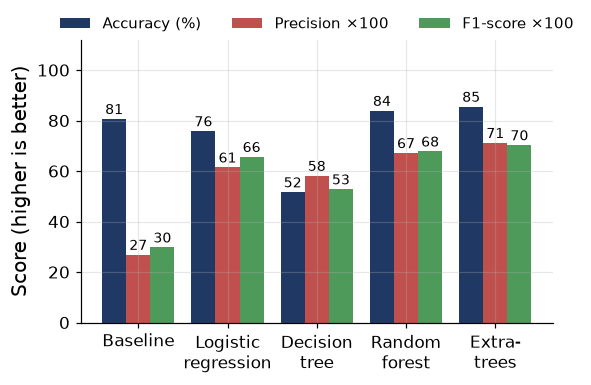

**Why this chart:** it picks the model fairly: every model is scored on graphs it never saw, and compared with the simple baselines it must beat.
**How we got it:** each model predicted every graph while that graph was hidden from training (62 rounds), and we scored the 62 predictions.
**X-axis:** the five models. **Y-axis:** score, higher is better (precision and F1 shown ×100).
**What it tells us:** the majority baseline has high accuracy (80.6%) but only **0.27 precision** and **0.30 F1**, because it never finds hub-split or native.
**Extra-Trees** is best on all three: accuracy **85.5%**, precision **0.71**, F1 **0.70**.
The depth-2 decision tree is too simple (51.6% accuracy). The hand-written rule (in the table, not drawn) is far worse than every learned model: learning from data beats a fixed rule.

In [7]:
def make_models():
    return {
        "Logistic regression": lambda: make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=2000, class_weight="balanced")),
        "Decision tree": lambda: DecisionTreeClassifier(max_depth=2, class_weight="balanced", random_state=SEED),
        "Random Forest": lambda: RandomForestClassifier(n_estimators=NTREES, class_weight="balanced_subsample", random_state=SEED, n_jobs=1),
        "Extra-Trees": lambda: ExtraTreesClassifier(n_estimators=NTREES, class_weight="balanced_subsample", random_state=SEED, n_jobs=1),
    }

def rule_pred(d):
    return np.where(d.work_in_hubs_share > 0, "hubsplit", "native")

def scores(yt, yp):
    return dict(accuracy=accuracy_score(yt, yp), precision=precision_score(yt, yp, average="macro", labels=CLASSES, zero_division=0),
                macro_f1=f1_score(yt, yp, average="macro", labels=CLASSES))

def leave_one_out(idx):
    # leave-one-graph-out over the rows in idx: returns predictions for each of them
    preds = {m: np.empty(len(idx), dtype=object) for m in ["Majority baseline", "Rule baseline", *make_models()]}
    for k, i in enumerate(idx):
        tr = np.delete(idx, k)
        vals, counts = np.unique(y[tr], return_counts=True)
        preds["Majority baseline"][k] = vals[counts.argmax()]
        preds["Rule baseline"][k] = rule_pred(df.iloc[[i]])[0]
        for name, mk in make_models().items():
            preds[name][k] = mk().fit(X[tr], y[tr]).predict(X[[i]])[0]
    return preds

ALL = np.arange(len(df))
LOGO_PRED = leave_one_out(ALL)
clf = pd.DataFrame({m: scores(y, p) for m, p in LOGO_PRED.items()}).T
display(clf.round(3))
RES["classifier_LOGO"] = clf.round(4).to_dict(orient="index")

# Slide chart (slide "Comparison with existing classifier models")
CMP = clf.loc[["Majority baseline", "Logistic regression", "Decision tree", "Random Forest", "Extra-Trees"], ["accuracy", "precision", "macro_f1"]] * 100
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(5.6, 3.8)); xs = np.arange(len(CMP)); w = .27
    for j, (m, lab_, c) in enumerate([("accuracy", "Accuracy (%)", "#1F3864"), ("precision", "Precision ×100", "#C0504D"), ("macro_f1", "F1-score ×100", "#4E9A5B")]):
        b = ax.bar(xs + (j - 1) * w, CMP[m], w, label=lab_, color=c); ax.bar_label(b, fmt="%.0f", fontsize=9, padding=1)
    ax.set_xticks(xs); ax.set_xticklabels(["Baseline", "Logistic\nregression", "Decision\ntree", "Random\nforest", "Extra-\ntrees"], fontsize=11)
    ax.set_ylim(0, 112); ax.set_ylabel("Score (higher is better)", fontsize=13); ax.tick_params(axis="y", labelsize=11)
    ax.legend(ncol=3, fontsize=10, loc="upper center", bbox_to_anchor=(.5, 1.13), frameon=False)
    save_slide(fig, "slide_comparison.png")
best = clf.drop(["Majority baseline", "Rule baseline"]).accuracy.idxmax()
display(Markdown(f"""**Why this chart:** it picks the model fairly: every model is scored on graphs it never saw, and compared with the simple baselines it must beat.
**How we got it:** each model predicted every graph while that graph was hidden from training (62 rounds), and we scored the 62 predictions.
**X-axis:** the five models. **Y-axis:** score, higher is better (precision and F1 shown ×100).
**What it tells us:** the majority baseline has high accuracy ({clf.loc['Majority baseline','accuracy']:.1%}) but only **{clf.loc['Majority baseline','precision']:.2f} precision** and **{clf.loc['Majority baseline','macro_f1']:.2f} F1**, because it never finds hub-split or native.
**{best}** is best on all three: accuracy **{clf.loc[best,'accuracy']:.1%}**, precision **{clf.loc[best,'precision']:.2f}**, F1 **{clf.loc[best,'macro_f1']:.2f}**.
The depth-2 decision tree is too simple ({clf.loc['Decision tree','accuracy']:.1%} accuracy). The hand-written rule (in the table, not drawn) is far worse than every learned model: learning from data beats a fixed rule."""))

### 5b. Train vs validation vs test
To report the usual three numbers we split the graphs:
* **Test set** = the 9 hub-sweep graphs generated with seed 202. They are kept aside and never used for training or tuning.
* **Training set** = the other 53 graphs.
* **Train score** = fit on the 53 and score on the same 53 (shows how well the model memorises).
* **Validation score** = leave-one-graph-out *inside* the 53 (an honest estimate while building).
* **Test score** = fit on the 53 and score on the 9 unseen graphs (the final exam).

train = 53 graphs, test = 9 graphs (unseen)


accuracy                   macro_f1                  
split                   Test  Train Validation     Test  Train Validation
model                                                                    
Extra-Trees            0.667  1.000      0.906    0.509  1.000      0.749
Logistic regression    0.778  0.868      0.774    0.600  0.799      0.631
Majority baseline      0.556  0.849      0.849    0.238  0.306      0.306
Random Forest          0.667  1.000      0.906    0.509  1.000      0.749

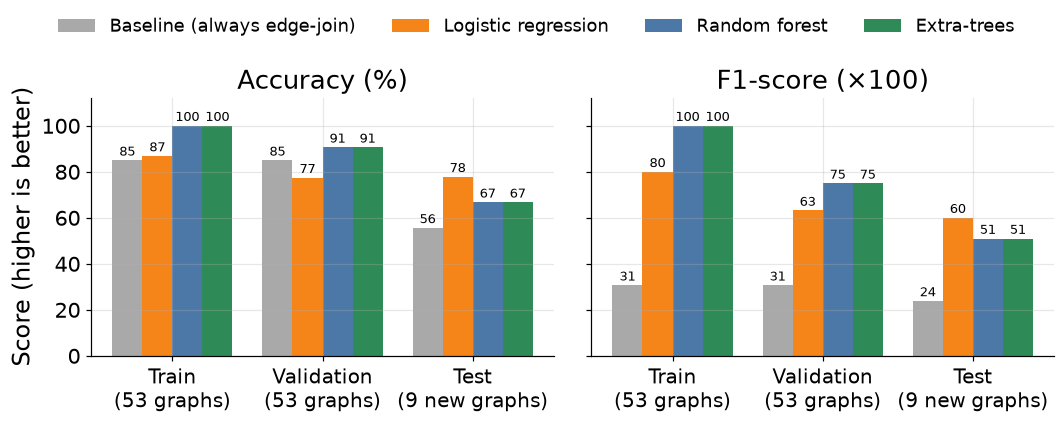

**Why this chart:** it shows the model is not just memorising: the honest validation and unseen-test scores still beat the baseline.
**How we got it:** the same models are trained on 53 graphs. We scored them on those 53 (train), with leave-one-out inside the 53 (validation), and on the 9 graphs they never saw (test).
**X-axis:** the three splits. **Y-axis:** score, higher is better (left accuracy, right F1-score ×100).
**What it tells us:** the tree models reach 100% on train because they memorise the data, so the train score is not trusted; validation and test are the honest numbers.
On validation, the tree models reach **90.6%** accuracy versus 84.9% for the baseline.
On the 9 unseen test graphs **every ML model beats the baseline**: the best is **Logistic regression** with **77.8%** accuracy and F1 **0.60**,
against **55.6%** and **0.24** for the baseline.
The test set is small (9 graphs), so one graph changes accuracy by 11 points. This is why our main numbers use leave-one-graph-out over all 62.

In [8]:
test_idx = np.where((df.family == "hub_sweep") & (df.seed == 202))[0]
train_idx = np.setdiff1d(ALL, test_idx)
print(f"train = {len(train_idx)} graphs, test = {len(test_idx)} graphs (unseen)")
VAL_PRED = leave_one_out(train_idx)
rows = []
for m in ["Majority baseline", "Logistic regression", "Random Forest", "Extra-Trees"]:
    if m == "Majority baseline":
        vals, counts = np.unique(y[train_idx], return_counts=True); maj = vals[counts.argmax()]
        p_tr, p_te = np.full(len(train_idx), maj, dtype=object), np.full(len(test_idx), maj, dtype=object)
    else:
        mdl = make_models()[m]().fit(X[train_idx], y[train_idx]); p_tr, p_te = mdl.predict(X[train_idx]), mdl.predict(X[test_idx])
    for split, yt, yp in [("Train", y[train_idx], p_tr), ("Validation", y[train_idx], VAL_PRED[m]), ("Test", y[test_idx], p_te)]:
        rows.append(dict(model=m, split=split, **scores(yt, yp)))
tvt = pd.DataFrame(rows)
display(tvt.pivot(index="model", columns="split", values=["accuracy", "macro_f1"]).round(3))
RES["train_val_test"] = tvt.round(4).to_dict(orient="records")

# Slide chart (slide "Results of Classification 2/4")
mods = ["Majority baseline", "Logistic regression", "Random Forest", "Extra-Trees"]; mc = [C["base"], "#F58518", "#4C78A8", C["ours"]]
short = {"Majority baseline": "Baseline (always edge-join)", "Logistic regression": "Logistic regression", "Random Forest": "Random forest", "Extra-Trees": "Extra-trees"}
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.9), sharey=True)
    for a, met, title in [(ax[0], "accuracy", "Accuracy (%)"), (ax[1], "macro_f1", "F1-score (×100)")]:
        for j, (m, c) in enumerate(zip(mods, mc)):
            v = tvt[tvt.model == m].set_index("split").loc[["Train", "Validation", "Test"], met] * 100
            b = a.bar(np.arange(3) + (j - 1.5) * .2, v, .2, color=c, label=short[m]); a.bar_label(b, fmt="%.0f", fontsize=8.5, padding=1)
        a.set_xticks(range(3)); a.set_xticklabels(["Train\n(53 graphs)", "Validation\n(53 graphs)", "Test\n(9 new graphs)"], fontsize=13); a.set_title(title); a.set_ylim(0, 112)
    ax[0].set_ylabel("Score (higher is better)")
    fig.legend(*ax[0].get_legend_handles_labels(), loc="upper center", ncol=4, fontsize=12, bbox_to_anchor=(.5, 1.02), frameon=False)
    fig.tight_layout(rect=(0, 0, 1, .92)); fig.savefig(f"{OUT}/slide_train_val_test.png", dpi=200); plt.show()
g = tvt.set_index(["model", "split"])
te = tvt[(tvt.split == "Test") & (tvt.model != "Majority baseline")].set_index("model")
bt = te.accuracy.idxmax()
display(Markdown(f"""**Why this chart:** it shows the model is not just memorising: the honest validation and unseen-test scores still beat the baseline.
**How we got it:** the same models are trained on 53 graphs. We scored them on those 53 (train), with leave-one-out inside the 53 (validation), and on the 9 graphs they never saw (test).
**X-axis:** the three splits. **Y-axis:** score, higher is better (left accuracy, right F1-score ×100).
**What it tells us:** the tree models reach 100% on train because they memorise the data, so the train score is not trusted; validation and test are the honest numbers.
On validation, the tree models reach **{g.loc[('Extra-Trees','Validation'),'accuracy']:.1%}** accuracy versus {g.loc[('Majority baseline','Validation'),'accuracy']:.1%} for the baseline.
On the 9 unseen test graphs **every ML model beats the baseline**: the best is **{bt}** with **{te.loc[bt,'accuracy']:.1%}** accuracy and F1 **{te.loc[bt,'macro_f1']:.2f}**,
against **{g.loc[('Majority baseline','Test'),'accuracy']:.1%}** and **{g.loc[('Majority baseline','Test'),'macro_f1']:.2f}** for the baseline.
The test set is small (9 graphs), so one graph changes accuracy by 11 points. This is why our main numbers use leave-one-graph-out over all 62."""))

### 5c. Where does the best classifier make mistakes? (confusion matrix) and what does it look at? (feature importance)

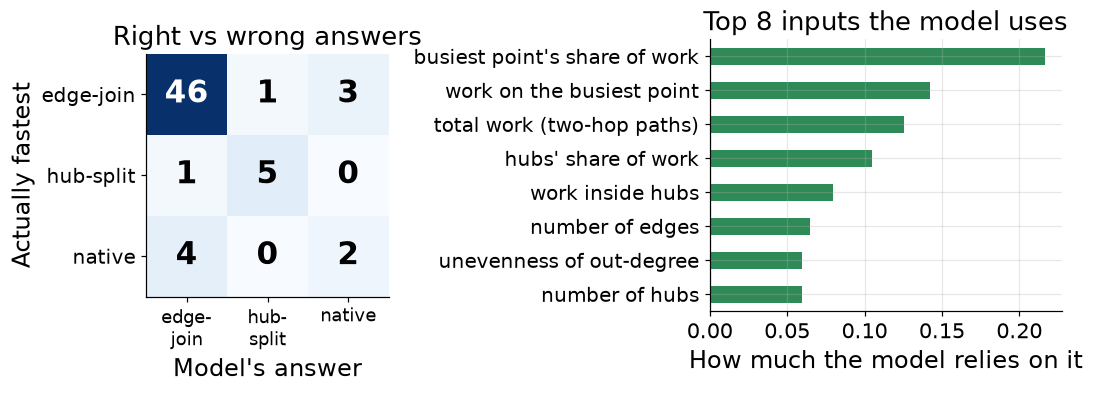

**Why this chart:** it explains the model's decisions: which cases it gets right, where it errs, and which features drive it. This makes the result defensible, not a black box.
**How we got it:** the confusion matrix counts actual vs predicted for the 62 held-out predictions (rows = actually fastest, columns = model's answer; the diagonal is correct). The importance bars (X-axis = how much the model relies on it) show how much each input reduced errors inside the trees.
**What it tells us:** edge-join is found **46 of 50** times, hub-split **5 of 6** and native **2 of 6**. Most mistakes (7 of 9) are between edge-join and native,
whose runtimes are often close, and the native class has only 6 examples to learn from. The most-used inputs are **busiest point's share of work**, **work on the busiest point** and **total work (two-hop paths)**:
the model decides mostly by how much work piles onto the busiest vertices, which matches what we saw in Step 2.

In [9]:
cm = confusion_matrix(y, LOGO_PRED["Extra-Trees"], labels=CLASSES)
et_full = ExtraTreesClassifier(n_estimators=NTREES, class_weight="balanced_subsample", random_state=SEED, n_jobs=1).fit(X, y)
imp = pd.Series(et_full.feature_importances_, index=FEATS).sort_values()
PLAIN = {"work_max_share": "busiest point's share of work", "log_max_work": "work on the busiest point", "log_work_sum": "total work (two-hop paths)",
         "work_in_hubs_share": "hubs' share of work", "log_hub_work": "work inside hubs", "log_num_edges": "number of edges", "out_gini": "unevenness of out-degree",
         "log_num_work_hubs": "number of hubs", "in_gini": "unevenness of in-degree", "log_in_p999": "top in-degree", "log_out_p999": "top out-degree",
         "log_num_vertices": "number of vertices", "active_fraction": "share of active vertices"}
TOP8 = pd.Series(imp.values, index=[PLAIN[f] for f in imp.index]).tail(8)
# Slide chart (slide "Comparison 2/2")
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1, 1.45]})
    ax[0].imshow(cm, cmap="Blues"); ax[0].grid(False)
    ax[0].set_xticks(range(3)); ax[0].set_xticklabels(["edge-\njoin", "hub-\nsplit", "native"], fontsize=12)
    ax[0].set_yticks(range(3)); ax[0].set_yticklabels(["edge-join", "hub-split", "native"], fontsize=13)
    for i in range(3):
        for j in range(3): ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=20, weight="bold", color="white" if cm[i, j] > 20 else "black")
    ax[0].set_xlabel("Model's answer"); ax[0].set_ylabel("Actually fastest"); ax[0].set_title("Right vs wrong answers")
    TOP8.plot.barh(ax=ax[1], color=C["ours"]); ax[1].set_xlabel("How much the model relies on it"); ax[1].set_title("Top 8 inputs the model uses")
    ax[1].tick_params(axis="y", labelsize=13)
    save_slide(fig, "slide_confusion_importance.png")
rec = cm.diagonal() / cm.sum(1)
display(Markdown(f"""**Why this chart:** it explains the model's decisions: which cases it gets right, where it errs, and which features drive it. This makes the result defensible, not a black box.
**How we got it:** the confusion matrix counts actual vs predicted for the 62 held-out predictions (rows = actually fastest, columns = model's answer; the diagonal is correct). The importance bars (X-axis = how much the model relies on it) show how much each input reduced errors inside the trees.
**What it tells us:** edge-join is found **{cm[0,0]} of {cm[0].sum()}** times, hub-split **{cm[1,1]} of {cm[1].sum()}** and native **{cm[2,2]} of {cm[2].sum()}**. Most mistakes ({cm[0,2] + cm[2,0]} of {cm.sum() - np.trace(cm)}) are between edge-join and native,
whose runtimes are often close, and the native class has only 6 examples to learn from. The most-used inputs are **{TOP8.index[-1]}**, **{TOP8.index[-2]}** and **{TOP8.index[-3]}**:
the model decides mostly by how much work piles onto the busiest vertices, which matches what we saw in Step 2."""))

### 5d. The selector: predict each strategy's runtime, pick the smallest
A classifier only says *which* strategy wins. Our **ML selector** goes one step further: a Random Forest **regressor** predicts the runtime of **all three** strategies for a graph, and we pick the smallest.
This is what we would actually deploy. It is evaluated with leave-one-graph-out too.

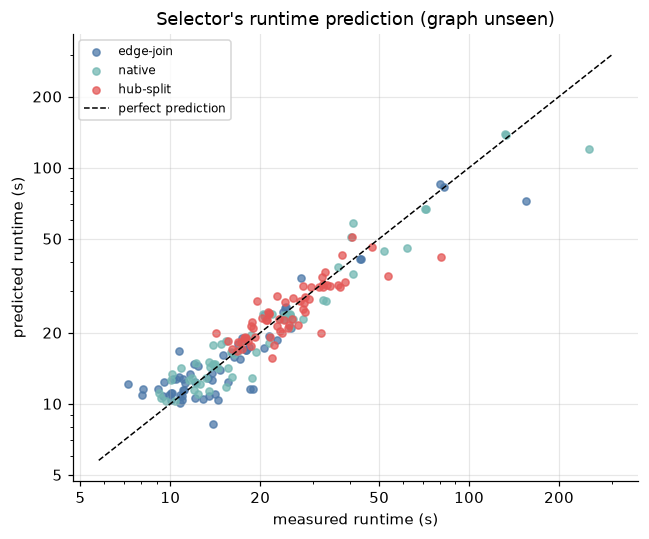

**Why this chart:** it checks the regressor behind the selector is accurate enough to rank the three strategies.
**How we got it:** for each held-out graph the regressor predicted three runtimes. Each dot is one prediction against the real Spark time (both axes are on a log scale, so 1, 10 and 100 s are evenly spaced).
**What it tells us:** the dots sit close to the dashed "perfect" line. The median prediction error is **10.1%**, which is accurate enough to rank the three strategies correctly for most graphs.

In [10]:
def fit_reg(Xtr, Ytr):
    return RandomForestRegressor(n_estimators=NTREES, min_samples_leaf=1, max_features=1.0, random_state=SEED, n_jobs=1).fit(Xtr, Ytr)

PRED = np.full_like(LOGT, np.nan)
for i in ALL:
    tr = np.delete(ALL, i); PRED[i] = fit_reg(X[tr], LOGT[tr]).predict(X[[i]])[0]
pick = PRED.argmin(1)
err = np.median(np.abs(np.exp(PRED) / T - 1)) * 100
fig, ax = plt.subplots(figsize=(6, 5))
for k, s in enumerate(STRATS): ax.scatter(T[:, k], np.exp(PRED[:, k]), s=22, alpha=.75, color=COL[NAME[s]], label=NAME[s])
lim = [T.min() * .8, T.max() * 1.2]; ax.plot(lim, lim, "k--", lw=1, label="perfect prediction")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("measured runtime (s)"); ax.set_ylabel("predicted runtime (s)")
for a in (ax.xaxis, ax.yaxis):
    a.set_major_locator(matplotlib.ticker.FixedLocator([5, 10, 20, 50, 100, 200])); a.set_major_formatter(matplotlib.ticker.ScalarFormatter()); a.set_minor_formatter(matplotlib.ticker.NullFormatter())
ax.set_title("Selector's runtime prediction (graph unseen)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(f"{OUT}/05d_regressor.png", dpi=130); plt.show()
RES["regressor_median_error_pct"] = round(float(err), 2)
display(Markdown(f"""**Why this chart:** it checks the regressor behind the selector is accurate enough to rank the three strategies.
**How we got it:** for each held-out graph the regressor predicted three runtimes. Each dot is one prediction against the real Spark time (both axes are on a log scale, so 1, 10 and 100 s are evenly spaced).
**What it tells us:** the dots sit close to the dashed "perfect" line. The median prediction error is **{err:.1f}%**, which is accurate enough to rank the three strategies correctly for most graphs."""))

### 5e. Is our selector actually better? Comparison with the baselines
We compare the ML selector with what a Spark user would do without it:
* **Always native**: the default GraphFrames way
* **Always edge-join**: the single best fixed choice
* **Always hub-split**
* **Rule**: hubs → hub-split, else native

**Primary metrics for the selector:**
* **Total runtime**: the sum of the real Spark time of the chosen strategy over all 62 graphs (lower is better)
* **Mean regret**: on average, how much slower the chosen strategy is than the fastest of the three for that graph (lower is better; 0% = always picked the fastest)

,total_time_s,mean_regret_pct,picked_fastest_pct,speedup_vs_native
Always native,1809.53,49.55,9.68,1.00
Always edge-join,1226.05,8.32,80.65,1.34
Always hub-split,1640.98,77.57,9.68,0.84
Rule,1490.22,56.94,14.52,0.95
ML selector,1069.53,4.63,82.26,1.38


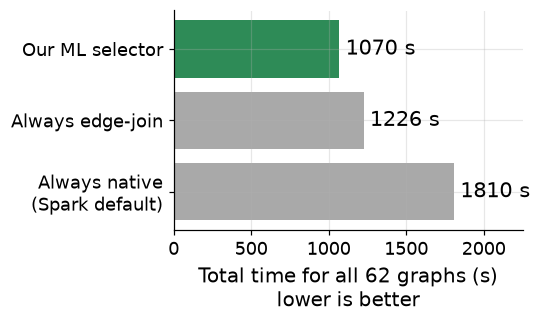

**Why this chart:** it is the main proof of our proposal: the selector gives the lowest real Spark time and the lowest slowdown of all the options.
**How we got it:** for every graph each policy chooses one strategy, and we add up the real measured Spark time of that choice. The regret of every policy is in the table above.
**X-axis:** total seconds for all 62 graphs (shorter bar = faster). **Y-axis:** the ways of choosing a method.
**What it tells us:** the ML selector has the **lowest total time (1070 s)** and the **lowest regret (4.6%)**.
That is **41% less time than always using native** (the default) and
**13% less than the best fixed strategy, edge-join**, whose regret (8.3%) is almost double ours.
It picks the fastest strategy for **82%** of the graphs.

In [11]:
def policy_scores(rows_idx, choice):
    t = T[rows_idx, choice]; best_t = T[rows_idx].min(1); nat = T[rows_idx, STRATS.index("native__aqe_on")]
    return dict(total_time_s=float(t.sum()), mean_regret_pct=float(np.mean(t / best_t - 1) * 100),
                picked_fastest_pct=float(np.mean(choice == T[rows_idx].argmin(1)) * 100), speedup_vs_native=float(np.exp(np.mean(np.log(nat / t)))))

def policies(rows_idx, pred):
    n = len(rows_idx)
    rule = np.where(df.work_in_hubs_share.values[rows_idx] > 0, STRATS.index("hypercube_unified__aqe_off"), STRATS.index("native__aqe_on"))
    return {"Always native": np.full(n, 1), "Always edge-join": np.full(n, 0), "Always hub-split": np.full(n, 2),
            "Rule": rule, "ML selector": pred[rows_idx].argmin(1)}

POL = pd.DataFrame({k: policy_scores(ALL, v) for k, v in policies(ALL, PRED).items()}).T
display(POL.round(2)); RES["policies_LOGO"] = POL.round(4).to_dict(orient="index")
# Slide chart (slide "Results of Classification 1/4")
TIME3 = POL.loc[["Always native", "Always edge-join", "ML selector"], "total_time_s"]
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(5.1, 3.2))
    b = ax.barh(["Always native\n(Spark default)", "Always edge-join", "Our ML selector"], TIME3.values, color=[C["base"], C["base"], C["ours"]])
    ax.bar_label(b, labels=[f"{v:.0f} s" for v in TIME3.values], padding=4, fontsize=14)
    ax.set_xlim(0, 2250); ax.set_xlabel("Total time for all 62 graphs (s)\nlower is better", fontsize=13); ax.tick_params(labelsize=12)
    save_slide(fig, "slide_total_time.png")
p = POL.loc
display(Markdown(f"""**Why this chart:** it is the main proof of our proposal: the selector gives the lowest real Spark time and the lowest slowdown of all the options.
**How we got it:** for every graph each policy chooses one strategy, and we add up the real measured Spark time of that choice. The regret of every policy is in the table above.
**X-axis:** total seconds for all 62 graphs (shorter bar = faster). **Y-axis:** the ways of choosing a method.
**What it tells us:** the ML selector has the **lowest total time ({p['ML selector','total_time_s']:.0f} s)** and the **lowest regret ({p['ML selector','mean_regret_pct']:.1f}%)**.
That is **{(1-p['ML selector','total_time_s']/p['Always native','total_time_s'])*100:.0f}% less time than always using native** (the default) and
**{(1-p['ML selector','total_time_s']/p['Always edge-join','total_time_s'])*100:.0f}% less than the best fixed strategy, edge-join**, whose regret ({p['Always edge-join','mean_regret_pct']:.1f}%) is almost double ours.
It picks the fastest strategy for **{p['ML selector','picked_fastest_pct']:.0f}%** of the graphs."""))

### 5f. Same comparison on the 9 unseen test graphs
Here the selector is trained on the 53 training graphs only and judged on the 9 test graphs from Step 5b.

,total_time_s,mean_regret_pct,picked_fastest_pct,speedup_vs_native
Always native,367.52,80.14,11.11,1.00
Always edge-join,228.79,18.51,55.56,1.47
Always hub-split,216.53,44.42,33.33,1.23
Rule,216.53,44.42,33.33,1.23
ML selector,181.31,7.31,66.67,1.59


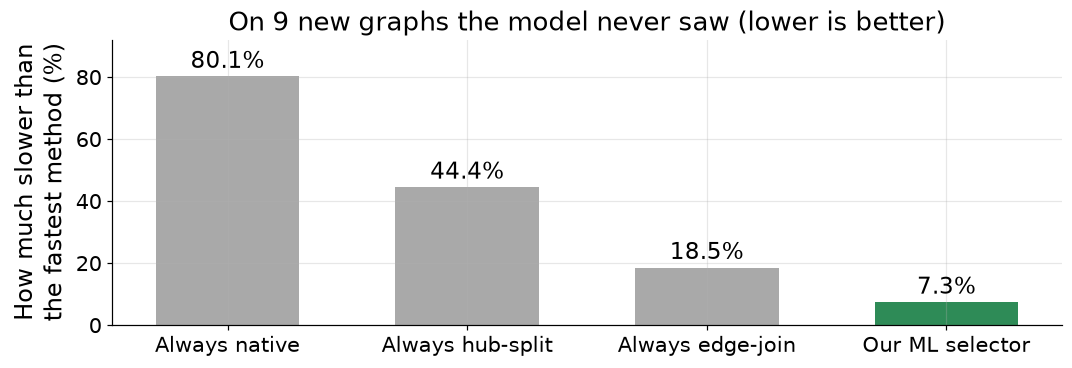

**Why this chart:** it repeats the proof on graphs the selector never saw, so the gain is not a training artefact.
**How we got it:** the regret measure (how much slower the chosen method was than the fastest one for that graph), only on the 9 held-out hub-sweep graphs, with a selector that never saw them. The rule policy gives the same picks as always hub-split here, so it is not drawn.
**X-axis:** the ways of choosing a method. **Y-axis:** average % slower than the fastest method (lower is better).
**What it tells us:** on new graphs the selector is still the best: **7.3%** regret against 18.5% for always edge-join
and 80.1% for always native. These test graphs include heavy-hub cases, where a fixed choice is costly and the selector helps the most.

In [12]:
reg53 = fit_reg(X[train_idx], LOGT[train_idx])
PRED_T = np.full_like(LOGT, np.nan); PRED_T[test_idx] = reg53.predict(X[test_idx])
POL_T = pd.DataFrame({k: policy_scores(test_idx, v) for k, v in policies(test_idx, PRED_T).items()}).T
display(POL_T.round(2)); RES["policies_test9"] = POL_T.round(4).to_dict(orient="index")
# Slide chart (slide "Results of Classification 4/4")
TEST4 = POL_T.loc[["Always native", "Always hub-split", "Always edge-join", "ML selector"], "mean_regret_pct"]
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(figsize=(10, 3.6))
    b = ax.bar(["Always native", "Always hub-split", "Always edge-join", "Our ML selector"], TEST4.values, color=[C["base"]] * 3 + [C["ours"]], width=.6)
    ax.bar_label(b, labels=[f"{x:.1f}%" for x in TEST4.values], fontsize=15, padding=2)
    ax.set_ylabel("How much slower than\nthe fastest method (%)"); ax.set_ylim(0, 92); ax.set_title("On 9 new graphs the model never saw (lower is better)")
    save_slide(fig, "slide_unseen_test.png")
display(Markdown(f"""**Why this chart:** it repeats the proof on graphs the selector never saw, so the gain is not a training artefact.
**How we got it:** the regret measure (how much slower the chosen method was than the fastest one for that graph), only on the 9 held-out hub-sweep graphs, with a selector that never saw them. The rule policy gives the same picks as always hub-split here, so it is not drawn.
**X-axis:** the ways of choosing a method. **Y-axis:** average % slower than the fastest method (lower is better).
**What it tells us:** on new graphs the selector is still the best: **{POL_T.loc['ML selector','mean_regret_pct']:.1f}%** regret against {POL_T.loc['Always edge-join','mean_regret_pct']:.1f}% for always edge-join
and {POL_T.loc['Always native','mean_regret_pct']:.1f}% for always native. These test graphs include heavy-hub cases, where a fixed choice is costly and the selector helps the most."""))

### 5g. How the time savings add up, and the headline numbers

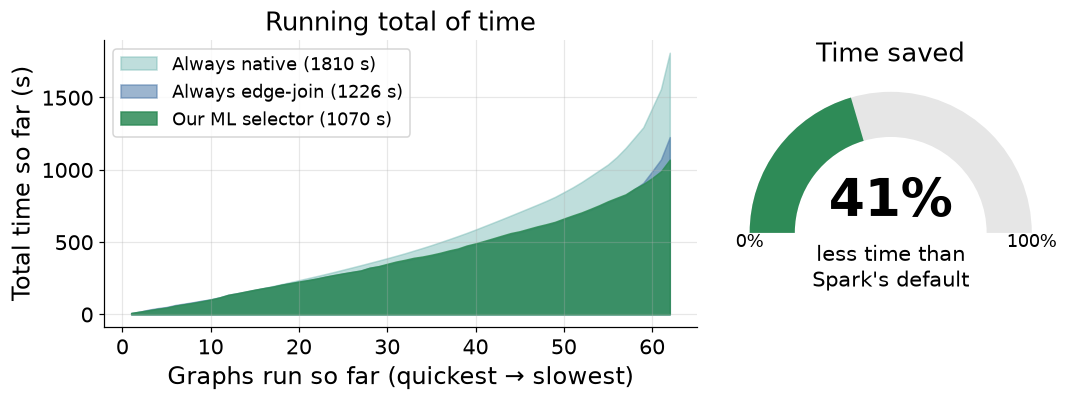

**Why this chart:** it turns the result into the headline number (time saved) and shows where the saving comes from.
**How we got it:** graphs are sorted from quickest to slowest (by native runtime), and each area shows the running total of time if we use that policy (area chart). The gauge shows the final saving against the default.
**X-axis:** graphs run so far, quickest to slowest. **Y-axis:** total seconds spent so far (lower area = less time).
**What it tells us:** against **native** the gap opens steadily, graph after graph. Against **edge-join** the selector is about equal on most graphs (both pick edge-join),
and then pulls ahead on the last, slowest, hub-heavy graphs, where it switches to hub-split: **164 s** saved on the last 5 graphs alone.
Overall the selector saves **41%** of the time of the default GraphFrames strategy.

In [13]:
ordr = np.argsort(T[:, 1])                                   # graphs from fastest to slowest (under native)
xs = np.arange(1, len(df) + 1)
cum = {n: np.cumsum(T[ordr, k]) for n, k in [("Always native", 1), ("Always edge-join", 0)]}
cum["ML selector"] = np.cumsum(T[ordr, pick[ordr]])
saved = (1 - POL.loc["ML selector", "total_time_s"] / POL.loc["Always native", "total_time_s"]) * 100
# Slide chart (slide "Results of Classification 3/4"): running total (area) + gauge
with plt.rc_context(SLIDE):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.9), gridspec_kw={"width_ratios": [1.75, 1]})
    ax[0].fill_between(xs, cum["Always native"], color=C["native"], alpha=.45, label=f"Always native ({cum['Always native'][-1]:.0f} s)")
    ax[0].fill_between(xs, cum["Always edge-join"], color=C["edge-join"], alpha=.55, label=f"Always edge-join ({cum['Always edge-join'][-1]:.0f} s)")
    ax[0].fill_between(xs, cum["ML selector"], color=C["ours"], alpha=.85, label=f"Our ML selector ({cum['ML selector'][-1]:.0f} s)")
    ax[0].set_xlabel("Graphs run so far (quickest → slowest)"); ax[0].set_ylabel("Total time so far (s)"); ax[0].legend(loc="upper left", fontsize=12); ax[0].set_title("Running total of time")
    a = ax[1]; a.axis("off"); a.set_xlim(-1.2, 1.2); a.set_ylim(-.45, 1.15); a.set_aspect("equal")
    a.add_patch(Wedge((0, 0), 1, 0, 180, width=.32, fc="#e6e6e6")); a.add_patch(Wedge((0, 0), 1, 180 - 180 * saved / 100, 180, width=.32, fc=C["ours"]))
    a.text(0, .12, f"{saved:.0f}%", ha="center", fontsize=34, weight="bold"); a.text(0, -.25, "less time than\nSpark's default", ha="center", fontsize=14, va="center")
    a.text(-1, -.1, "0%", ha="center", fontsize=12); a.text(1, -.1, "100%", ha="center", fontsize=12); a.set_title("Time saved", fontsize=17)
    save_slide(fig, "slide_running_total.png")
RES["time_saved_vs_native_pct"] = round(float(saved), 2)
last5 = (cum["Always edge-join"][-1] - cum["Always edge-join"][-6]) - (cum["ML selector"][-1] - cum["ML selector"][-6])
display(Markdown(f"""**Why this chart:** it turns the result into the headline number (time saved) and shows where the saving comes from.
**How we got it:** graphs are sorted from quickest to slowest (by native runtime), and each area shows the running total of time if we use that policy (area chart). The gauge shows the final saving against the default.
**X-axis:** graphs run so far, quickest to slowest. **Y-axis:** total seconds spent so far (lower area = less time).
**What it tells us:** against **native** the gap opens steadily, graph after graph. Against **edge-join** the selector is about equal on most graphs (both pick edge-join),
and then pulls ahead on the last, slowest, hub-heavy graphs, where it switches to hub-split: **{last5:.0f} s** saved on the last 5 graphs alone.
Overall the selector saves **{saved:.0f}%** of the time of the default GraphFrames strategy."""))

## Step 6: Save and share reports
We save three things:
1. `datasets/derived/review/results.json`: every number shown above
2. `datasets/derived/review/*.png`: all the charts (used in our slides and report)
3. **Tableau sources for every slide chart** (`datasets/derived/review/tableau/slide_*.csv`): one small CSV behind each chart in our presentation, so each slide chart can be rebuilt (and filtered) in Tableau. The cell reads every file back and checks it gives the same numbers as the notebook.
4. **Tableau "Decision Explorer"** (`datasets/derived/review/tableau/`). These are not the same charts again. They are a **per-graph decision log** that Tableau can filter and drill into:
   for each graph, what the selector predicted, what it picked, what was actually fastest, and how many seconds it saved compared with native and edge-join.
   In Tableau you can filter by family or hub share and see **where** the selector helps or makes mistakes. That is something the static charts above cannot do.

wrote /home/claude/rayirth556/hypergraph/datasets/derived/review/tableau/decision_explorer.csv (62, 21) | /home/claude/rayirth556/hypergraph/datasets/derived/review/tableau/policy_kpis.csv (5, 5) | results.json


,slide_chart,tableau_source,rows,how_to_build_in_Tableau
0,slide_preprocessing.png,slide_preprocessing.csv,6,"Bar: graph_family on Rows, SUM of edge-join / ..."
1,slide_total_time.png,slide_total_time.csv,3,"Bar: policy on Rows, total_time_s on Columns"
2,slide_train_val_test.png,slide_train_val_test.csv,12,"Bar: split on Columns, model on Colour, accura..."
3,slide_running_total.png,slide_running_total.csv,62,"Area: graphs_run on Columns, the three cum_s_*..."
4,slide_unseen_test.png,slide_unseen_test.csv,4,"Bar: policy on Columns, mean_regret_pct on Rows"
5,slide_comparison.png,slide_comparison.csv,5,"Bar: model on Columns, Measure Values (accurac..."
6,slide_confusion.png,slide_confusion.csv,9,"Highlight table: actually_fastest on Rows, mod..."
7,slide_importance.png,slide_importance.csv,8,"Bar: input on Rows, importance on Columns, sorted"


All 8 slide-chart sources written, read back and matched.


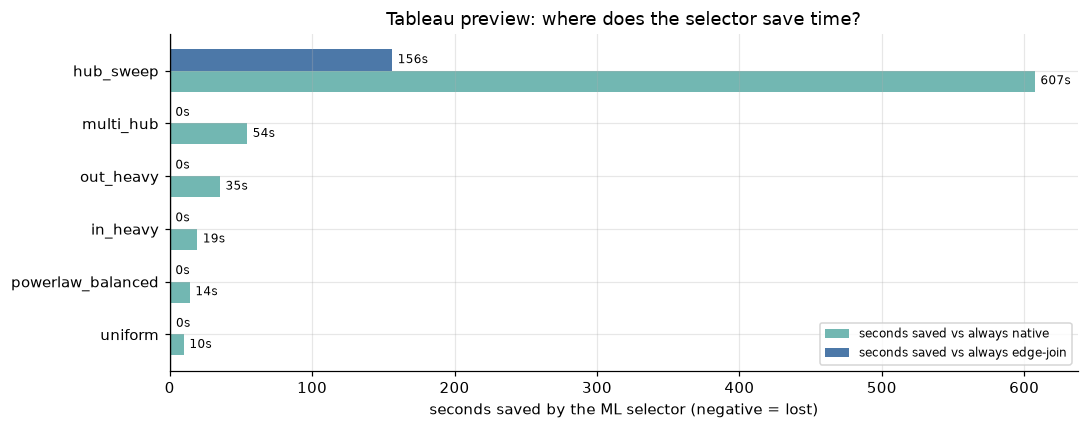

selector picked the fastest strategy on 51 of 62 graphs; the misses:


,graph_id,family,selector_pick,actual_fastest,regret_pct,saved_vs_native_s
27,uniform-medium-s101-5b7704b2,uniform,native,edge-join,53.4,0.00
11,multi_hub-small-s101-cea55efc,multi_hub,edge-join,native,51.7,-6.30
43,hubsweep-H2-w50-n100k-s101-522cba11,hub_sweep,native,edge-join,48.0,0.00
48,hubsweep-H4-w50-n100k-s101-4f057b16,hub_sweep,edge-join,native,34.8,-3.59
49,hubsweep-H4-w50-n100k-s202-8ce61dba,hub_sweep,native,edge-join,26.9,0.00
37,hubsweep-H1-w95-n100k-s202-921f70ae,hub_sweep,edge-join,hub-split,20.5,9.79
28,uniform-medium-s202-98ee4d97,uniform,edge-join,native,18.7,-2.99
32,hubsweep-H1-w50-n100k-s202-58e46ccc,hub_sweep,edge-join,native,18.4,-2.24
31,hubsweep-H1-w50-n100k-s101-9ddafffc,hub_sweep,native,edge-join,12.4,-0.00
47,hubsweep-H2-w98-n100k-s101-cc0c0e8f,hub_sweep,hub-split,edge-join,1.7,13.18


**Why this chart:** it shows how the shared Tableau file is useful: it reveals where the selector saves time and what its mistakes cost.
**How we got it:** we summed the per-graph "seconds saved" columns of the Tableau file by family, and listed the graphs where the pick was not the fastest.
**What it tells us:** most of the saving comes from **hub_sweep** graphs (hub-heavy ones), which is exactly where a smart choice matters. Against edge-join the saving is smaller,
because edge-join is already right for most graphs. The selector is wrong on 11 graphs, but these are mostly small, close calls: together they cost only
**33 s** more than the fastest choice,
against **740 s** saved compared with native over all graphs.
**In Tableau:** *Connect → Text file → `decision_explorer.csv`*, put `family` on Rows, `SUM(saved_vs_native_s)` on Columns, `correct` on Colour, and add `hub_work_share_pct` as a filter.

In [14]:
TAB = os.path.join(OUT, "tableau"); os.makedirs(TAB, exist_ok=True)
dec = pd.DataFrame({
    "graph_id": df.graph_id, "family": df.family, "hub_count": df.hub_count.fillna(0).astype(int),
    "hub_work_share_pct": (df.work_in_hubs_share * 100).round(1), "busiest_vertex_share_pct": (df.work_max_share * 100).round(1),
    "vertices": df.vertices, "edges": df.edges, "two_hop_paths": df.two_hop_paths,
    **{f"pred_s_{NAME[s].replace('-', '_')}": np.exp(PRED[:, k]).round(2) for k, s in enumerate(STRATS)},
    **{f"actual_s_{NAME[s].replace('-', '_')}": T[:, k].round(2) for k, s in enumerate(STRATS)},
    "selector_pick": [NAME[STRATS[k]] for k in pick], "actual_fastest": [NAME[STRATS[k]] for k in T.argmin(1)],
})
dec["correct"] = dec.selector_pick == dec.actual_fastest
dec["selector_s"] = T[ALL, pick].round(2)
dec["saved_vs_native_s"] = (T[:, 1] - dec.selector_s).round(2)
dec["saved_vs_edgejoin_s"] = (T[:, 0] - dec.selector_s).round(2)
dec["regret_pct"] = ((dec.selector_s / T.min(1) - 1) * 100).round(1)
kpi = pd.DataFrame([dict(policy=k, **v) for k, v in RES["policies_LOGO"].items()])
dec.to_csv(f"{TAB}/decision_explorer.csv", index=False); kpi.to_csv(f"{TAB}/policy_kpis.csv", index=False)
json.dump(RES, open(f"{OUT}/results.json", "w"), indent=1, default=float)
print("wrote", f"{TAB}/decision_explorer.csv", dec.shape, "|", f"{TAB}/policy_kpis.csv", kpi.shape, "| results.json")

# One Tableau source per slide chart, plus how to build each chart in Tableau
SLIDE_SOURCES = {
    "slide_preprocessing.csv": (FASTEST.reset_index().rename(columns={"family": "graph_family"}),
                                "Bar: graph_family on Rows, SUM of edge-join / hub-split / native on Columns (stacked)"),
    "slide_total_time.csv": (TIME3.rename("total_time_s").rename_axis("policy").reset_index(), "Bar: policy on Rows, total_time_s on Columns"),
    "slide_train_val_test.csv": (tvt[tvt.model.isin(mods)][["model", "split", "accuracy", "macro_f1"]], "Bar: split on Columns, model on Colour, accuracy (or macro_f1) on Rows"),
    "slide_running_total.csv": (pd.DataFrame({"graphs_run": xs, **{f"cum_s_{k.replace(' ', '_').replace('-', '_').lower()}": v for k, v in cum.items()}}),
                                "Area: graphs_run on Columns, the three cum_s_* measures on Rows (Measure Values)"),
    "slide_unseen_test.csv": (TEST4.rename("mean_regret_pct").rename_axis("policy").reset_index(), "Bar: policy on Columns, mean_regret_pct on Rows"),
    "slide_comparison.csv": (CMP.rename_axis("model").reset_index(), "Bar: model on Columns, Measure Values (accuracy, precision, macro_f1) on Rows"),
    "slide_confusion.csv": (pd.DataFrame([(CLASSES[i], CLASSES[j], int(cm[i, j])) for i in range(3) for j in range(3)], columns=["actually_fastest", "model_answer", "graphs"]),
                            "Highlight table: actually_fastest on Rows, model_answer on Columns, SUM(graphs) on Colour and Label"),
    "slide_importance.csv": (TOP8.rename("importance").rename_axis("input").reset_index(), "Bar: input on Rows, importance on Columns, sorted"),
}
guide = []
for fn, (t, how) in SLIDE_SOURCES.items():
    t.to_csv(f"{TAB}/{fn}", index=False)
    back = pd.read_csv(f"{TAB}/{fn}")
    num = t.select_dtypes("number").values
    assert back.shape == t.shape and np.allclose(back.select_dtypes("number").values, num), fn
    guide.append(dict(slide_chart=fn.replace(".csv", ".png"), tableau_source=fn, rows=len(back), how_to_build_in_Tableau=how))
display(pd.DataFrame(guide))
print("All", len(guide), "slide-chart sources written, read back and matched.")

# Preview of the Tableau view, read back from the file exactly as Tableau would
L = pd.read_csv(f"{TAB}/decision_explorer.csv")
byfam = L.groupby("family")[["saved_vs_native_s", "saved_vs_edgejoin_s"]].sum().sort_values("saved_vs_native_s")
fig, ax = plt.subplots(figsize=(10, 4))
yy = np.arange(len(byfam))
ax.barh(yy - .2, byfam.saved_vs_native_s, .4, color=COL["native"], label="seconds saved vs always native")
ax.barh(yy + .2, byfam.saved_vs_edgejoin_s, .4, color=COL["edge-join"], label="seconds saved vs always edge-join")
ax.set_yticks(yy); ax.set_yticklabels(byfam.index); ax.axvline(0, c="k", lw=.8); ax.set_xlabel("seconds saved by the ML selector (negative = lost)")
for yv, (a_, b_) in enumerate(zip(byfam.saved_vs_native_s, byfam.saved_vs_edgejoin_s)):
    ax.text(max(a_, 0) + 4, yv - .2, f"{a_:.0f}s", va="center", fontsize=8); ax.text(max(b_, 0) + 4, yv + .2, f"{b_:.0f}s", va="center", fontsize=8)
ax.set_title("Tableau preview: where does the selector save time?"); ax.legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(f"{OUT}/06_tableau_preview.png", dpi=130); plt.show()
wrong = L[~L.correct].sort_values("regret_pct", ascending=False)
print(f"selector picked the fastest strategy on {int(L.correct.sum())} of {len(L)} graphs; the misses:")
display(wrong[["graph_id", "family", "selector_pick", "actual_fastest", "regret_pct", "saved_vs_native_s"]].head(11))
best_f = byfam.saved_vs_native_s.idxmax()
display(Markdown(f"""**Why this chart:** it shows how the shared Tableau file is useful: it reveals where the selector saves time and what its mistakes cost.
**How we got it:** we summed the per-graph "seconds saved" columns of the Tableau file by family, and listed the graphs where the pick was not the fastest.
**What it tells us:** most of the saving comes from **{best_f}** graphs (hub-heavy ones), which is exactly where a smart choice matters. Against edge-join the saving is smaller,
because edge-join is already right for most graphs. The selector is wrong on {len(wrong)} graphs, but these are mostly small, close calls: together they cost only
**{(wrong.selector_s - L.loc[wrong.index, ['actual_s_edge_join','actual_s_native','actual_s_hub_split']].min(axis=1)).sum():.0f} s** more than the fastest choice,
against **{byfam.saved_vs_native_s.sum():.0f} s** saved compared with native over all graphs.
**In Tableau:** *Connect → Text file → `decision_explorer.csv`*, put `family` on Rows, `SUM(saved_vs_native_s)` on Columns, `correct` on Colour, and add `hub_work_share_pct` as a filter."""))

## Reproducibility check
Fixed seeds, `n_jobs=1` and no random sampling mean that every run gives exactly the same numbers. The cell below compares this run with the numbers in our report and slides.

In [15]:
expected = {   # numbers in our report / slides (leave-one-graph-out, 62 graphs)
    "majority accuracy": (clf.loc["Majority baseline", "accuracy"], 0.806),
    "majority F1-score": (clf.loc["Majority baseline", "macro_f1"], 0.298),
    "majority precision": (clf.loc["Majority baseline", "precision"], 0.269),
    "decision tree accuracy": (clf.loc["Decision tree", "accuracy"], 0.516),
    "extra-trees precision": (clf.loc["Extra-Trees", "precision"], 0.712),
    "random forest accuracy": (clf.loc["Random Forest", "accuracy"], 0.839),
    "extra-trees accuracy": (clf.loc["Extra-Trees", "accuracy"], 0.855),
    "extra-trees macro-F1": (clf.loc["Extra-Trees", "macro_f1"], 0.703),
    "selector total time (s)": (POL.loc["ML selector", "total_time_s"], 1070),
    "always edge-join total time (s)": (POL.loc["Always edge-join", "total_time_s"], 1226),
    "always native total time (s)": (POL.loc["Always native", "total_time_s"], 1810),
    "selector mean regret (%)": (POL.loc["ML selector", "mean_regret_pct"], 4.6),
    "always edge-join mean regret (%)": (POL.loc["Always edge-join", "mean_regret_pct"], 8.3),
}
chk = pd.DataFrame([dict(metric=k, this_run=round(v, 3), report=r, match=abs(round(v, 3 if r < 1 else 1 if r < 100 else 0) - r) < 1e-9 or abs(v - r) < (5e-4 if r < 1 else .05 if r < 100 else .5)) for k, (v, r) in expected.items()])
display(chk)
print("ALL NUMBERS MATCH THE REPORT" if chk.match.all() else "SOME NUMBERS DIFFER - check library versions / data file")

,metric,this_run,report,match
0,majority accuracy,0.806,0.806,True
1,majority F1-score,0.298,0.298,True
2,majority precision,0.269,0.269,True
3,decision tree accuracy,0.516,0.516,True
4,extra-trees precision,0.712,0.712,True
5,random forest accuracy,0.839,0.839,True
6,extra-trees accuracy,0.855,0.855,True
7,extra-trees macro-F1,0.703,0.703,True
8,selector total time (s),1069.535,1070.000,True
9,always edge-join total time (s),1226.049,1226.000,True


ALL NUMBERS MATCH THE REPORT
